# <font color='black'> Регрессионный анализ: продолжение, 2026 </font>
# <font color='black'>Практическое занятие 4 </font>


## <font color='black'>Модель множественной линейной регрессии. Мультиколлинеарность. Гетероскедастичность. Нетипичные наблюдения </font>
На этом занятии мы продолжим работать с данными из статьи [Kalenborn C., Lessman C., 2013](https://yadi.sk/i/nlEQUoWKiqY0UA). Одна из частей анализа в данной статье выполнена на основе cross-section data (использованы усредненные данные за 2005 - 2010 гг.). Авторы изучают взаимосвязь уровня коррупции и демократии, предполагая, что ее характер зависит от значений показателя свободы прессы. Кратко о данных:
* cpi - уровень коррупции: Corruption Perception Index. Непрерывная шкала от 0 до 10, где 10 означает наиболее высокий уровень коррупции.
* dem - индекс демократии: Vanhanen’s democratization index. Непрерывная шкала от 0 до 100, где 100 означает максимальное значение уровня демократии.
* fp - свобода прессы: Freedom House. Приведен к непрерывной шкале от 0 до 100, где 100 - наиболее высокое значение свободы прессы.
* loggdppc - натуральный логарифм ВВП на душу населения. World Bank.
* stab - уровень политической стабильности. Индекс построен на основе показателей "Political Stability" и "Absence of Violence/Terrorism" из the Worldwide Governance Indicators. Непрерывная шкала от -2.5 до 2.5, где 2.5 соответствует наиболее высокому уровню политической стабильности.
* britcol - дамми-переменная, где 1 - бывшая британская колония.

In [21]:
import pandas as pd
import statsmodels.formula.api as smf
import seaborn as sns
import numpy as np
import matplotlib.pyplot as mpl
%matplotlib inline

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.diagnostic import het_white
from statsmodels.stats.diagnostic import het_goldfeldquandt

from statsmodels.stats.outliers_influence import outlier_test

Откроем массив данных:

In [22]:
lab4 = pd.read_stata('lab1.dta')
lab4 = lab4.dropna()

И оценим линейную множественную регрессионную модель с уже знакомой Вам спецификацией:

In [23]:
m1 = smf.ols(formula = "cpi ~ dem + fp + loggdppc + britcol + stab", data = lab4).fit(cov_type="HC3")
print(m1.summary())

                            OLS Regression Results                            
Dep. Variable:                    cpi   R-squared:                       0.745
Model:                            OLS   Adj. R-squared:                  0.738
Method:                 Least Squares   F-statistic:                     73.14
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           5.83e-40
Time:                        10:20:10   Log-Likelihood:                -249.04
No. Observations:                 170   AIC:                             510.1
Df Residuals:                     164   BIC:                             528.9
Df Model:                           5                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     12.2657      0.653     18.781      0.0

С точки зрения такого сюжета, как мультиколлинеарность, полезно будет посмотреть на то, насколько сильно связаны объясняющие переменные в модели. Выведем набор графиков, включающий и визуализацию распределений самих переменных (по главной диагонали), и диаграммы рассеяния.

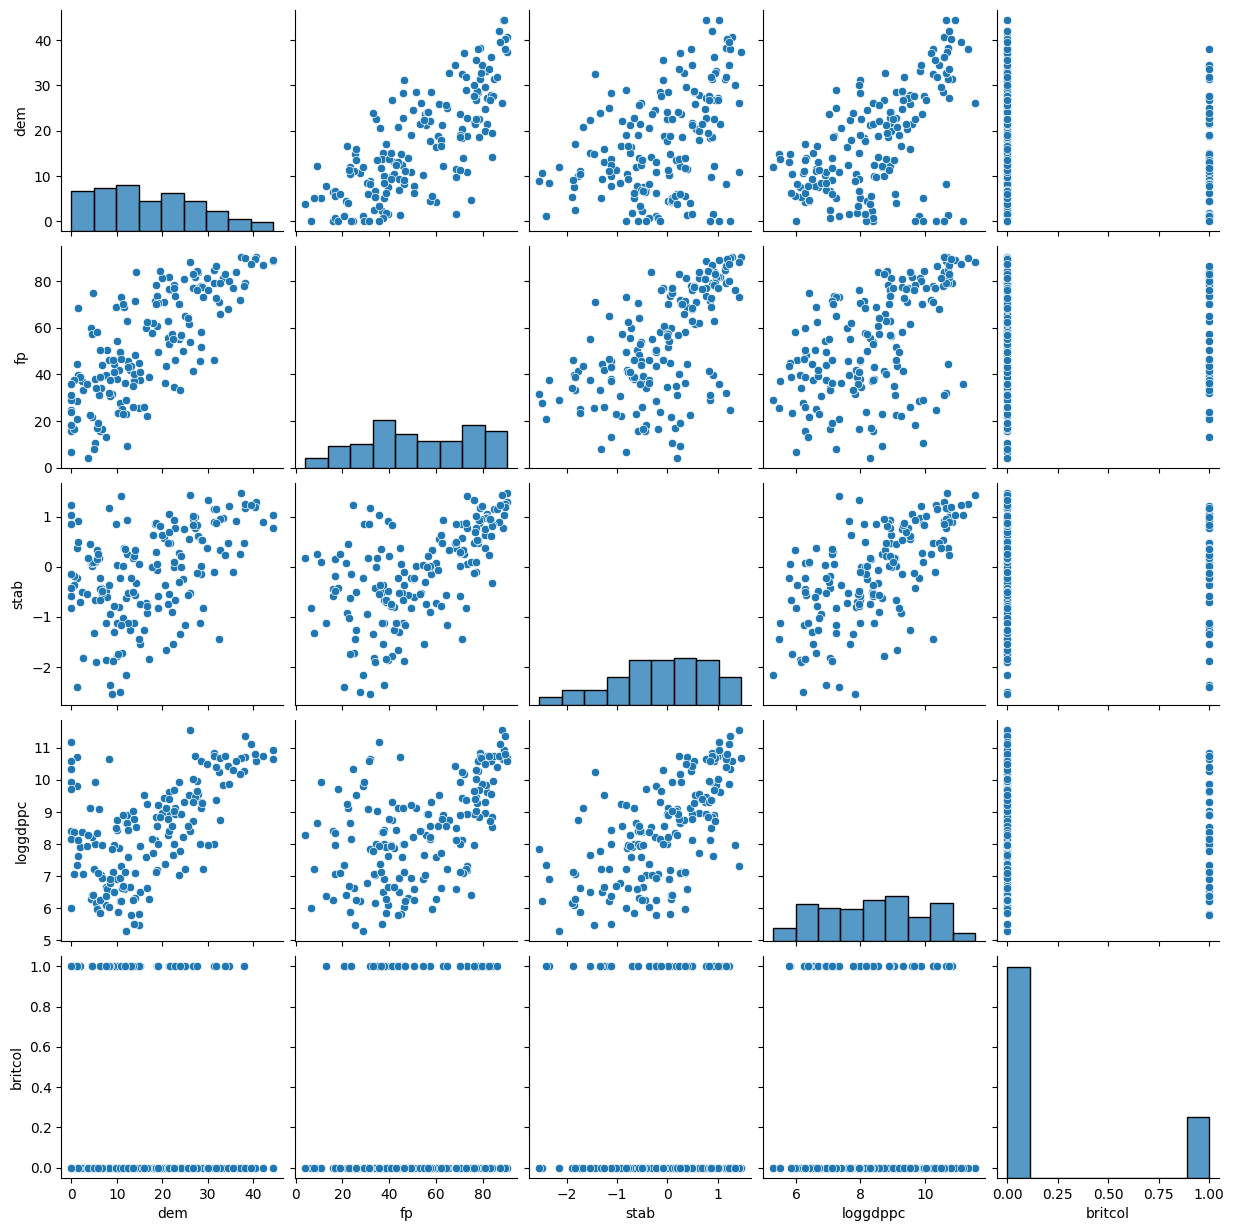

In [4]:
sns.pairplot(lab4[["dem", "fp", "stab", "loggdppc", "britcol"]])

Также ниже представим корреляционную матрицу для предикторов:

In [5]:
lab4[["dem", "fp", "stab", "loggdppc", "britcol"]].corr().round(3)

,dem,fp,stab,loggdppc,britcol
dem,1.000,0.755,0.409,0.559,-0.071
fp,0.755,1.000,0.583,0.511,0.030
stab,0.409,0.583,1.000,0.633,-0.017
loggdppc,0.559,0.511,0.633,1.000,-0.043
britcol,-0.071,0.030,-0.017,-0.043,1.000


Рассчитаем показатели variance inflation factor:

In [6]:
X = lab4[["dem", "fp", "stab", "loggdppc", "britcol"]]
X = add_constant(X)

vif_data = pd.DataFrame({'variables':X.columns[1:], 'VIF':[variance_inflation_factor(X.values, i+1) for i in range(len(X.columns[1:]))]})
print(vif_data)

  variables       VIF
0       dem  2.788427
1        fp  3.039657
2      stab  2.103787
3  loggdppc  2.061774
4   britcol  1.024839


Также для тренировки самостоятельно посчитаем VIF для показателя dem, построив предварительно соответствующую вспомогательную модель и выгрузив ее коэффициент детерминации:

In [7]:
m1_aux = smf.ols(formula = "dem ~ fp + loggdppc + britcol + stab", data = lab4).fit()

vif_dem = 1/(1-m1_aux.rsquared)
print(vif_dem)

2.788427475636641


Для лучшего понимания, как связаны $R^2$ из вспомогательной регрессионной модели и значения VIF, построим график:

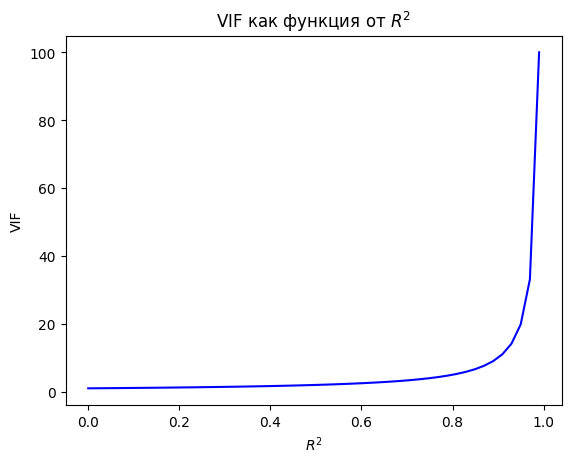

In [8]:
rsquared = np.linspace(0, 0.99)
VIF = 1/(1-rsquared)
fig, axes = mpl.subplots()
mpl.plot(rsquared, VIF, 'b')
axes.set_xlabel('$R^2$')
axes.set_ylabel('VIF')
mpl.title('VIF как функция от $R^2$')
mpl.show()

Проверим, можно ли говорить про гомоскедастичность (здравый смысл подсказывает, что надеяться не стоит), но тем не менее, реализуем определенные диагностики. Для начала построим график, показывающий, как связаны остатки в квадрате и одна из объясняющих переменных - к примеру, ключевой предиктор (dem).

Text(0, 0.5, 'Остатки в квадрате')

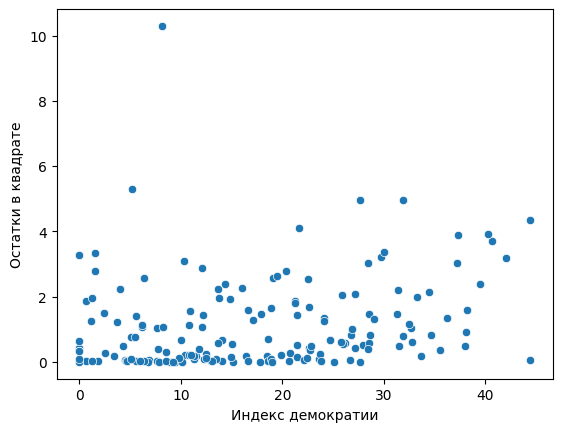

In [9]:
fitted = m1.predict()
residuals_sq = m1.resid**2
fig, ax = mpl.subplots()
sns.scatterplot(x = lab4['dem'], y = residuals_sq)
ax.set_xlabel( "Индекс демократии")
ax.set_ylabel( "Остатки в квадрате")

Можно не рассматривать объясняющие переменные по отдельности, а  построить график, показывающий, как связаны остатки в квадрате и предсказанные значения по модели ($\hat{y}$ как линейная комбинация предикторов)

Text(0, 0.5, 'Квадраты остатков')

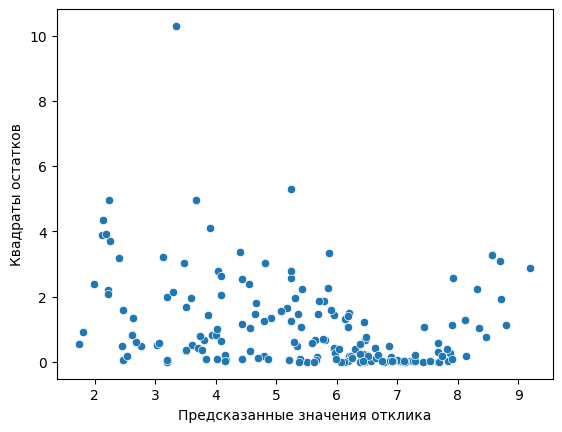

In [10]:
fitted = m1.predict()
residuals_sq = m1.resid**2
fig, ax = mpl.subplots()
sns.scatterplot(x = fitted, y = residuals_sq)
ax.set_xlabel( "Предсказанные значения отклика")
ax.set_ylabel( "Квадраты остатков")

Есть и формальные тесты для проверки гипотезы о гомоскедастичности. К примеру, тест Бреуша-Пагана, предполагающий более экономную спецификацию вспомогательной модели по сравнению с тестом Уайта (остатки в квадрате регрессируются на исходные объясняющие переменные, не учитываются квадратичные эффекты и совместные эффекты). Проинтерпретируем его результаты на основании p-value

In [11]:
bp_test = het_breuschpagan(m1.resid, m1.model.exog)
stat, p_value = bp_test[0:2]
print(f'Statistic: {stat}, P-Value: {p_value}')

Statistic: 23.11185501963807, P-Value: 0.0003213431262779054


Кроме этого, мы можем рассмотреть частный случай гетероскедастичности. Мы можем предположить, что дисперсия остатков монотонно возрастает/убывает с ростом предиктора. Для иллюстрации возьмем предиктор "loggdppc"

Отвержение нулевой гипотезы говорит не в целом о гетероскедастичности, а наличии определенного паттерна, задающего различия в дисперсии остатков

В этом тесте возможно задать и одностороннюю альтернативу (increasing / decreasing), но будьте аккуратны, чтобы не ошибиться с направлением альтернативы и не получить противоположный результат

In [12]:
gq_test = het_goldfeldquandt(lab4.cpi, X, idx = 4, drop = 0.2, alternative = 'two-sided', result_object=True)
stat, p_value, alternative = gq_test[0:3]
print(f'Statistic: {stat}, P-Value: {p_value}, alternative: {alternative}')

Statistic: 3.8975444126112513, P-Value: 1.2676056266780962e-07, alternative: two-sided


Переоценим модель с исходными стандартными ошибками и сравним результаты с моделью, которая оценена со стандартными ошибками, состоятельными в условиях гетероскедастичности (HC3)

Обратите внимание, оценки коэффициентов остаются без изменений, меняются только стандартные ошибки, так как используем специальную матрицу весов HC3 для ошибок

In [13]:
m1_1 = smf.ols(formula = "cpi ~ dem + fp + stab + loggdppc + britcol", data = lab4).fit()
print(m1_1.summary())

                            OLS Regression Results                            
Dep. Variable:                    cpi   R-squared:                       0.745
Model:                            OLS   Adj. R-squared:                  0.738
Method:                 Least Squares   F-statistic:                     95.99
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           7.22e-47
Time:                        10:20:09   Log-Likelihood:                -249.04
No. Observations:                 170   AIC:                             510.1
Df Residuals:                     164   BIC:                             528.9
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     12.2657      0.663     18.506      0.0

In [14]:
comparison = pd.DataFrame({
    'coef_HC3': m1.params,
    'se_HC3': m1.bse,
    'coef_original': m1_1.params,
    'se_original': m1_1.bse,
    'se_ratio': m1.bse / m1_1.bse
})

print("Сравнение стандартных ошибок исходных и HC3:")
print(comparison.round(3))

Сравнение стандартных ошибок исходных и HC3:
           coef_HC3  se_HC3  coef_original  se_original  se_ratio
Intercept    12.266   0.653         12.266        0.663     0.985
britcol      -0.416   0.206         -0.416        0.199     1.039
dem          -0.013   0.012         -0.013        0.012     1.040
fp           -0.018   0.007         -0.018        0.006     1.103
loggdppc     -0.674   0.078         -0.674        0.077     1.016
stab         -0.548   0.123         -0.548        0.127     0.970


Проверим, есть ли в нашем массиве нетипичные наблюдения. Для начала рассмотрим нетипичные наблюдения по предикторам.

In [15]:
leverage = m1.get_influence().hat_matrix_diag

leverage_data = lab4[leverage > 2*np.mean(leverage)]
leverage_data

,country,loggdppc,britcol,dem,stab,fp,cpi
24,Brunei Darussalam,10.341743,0,0.000000,1.238990,24.500000,3.933000
82,Israel,10.257659,0,32.433334,-1.442761,71.000000,3.349667
93,Kuwait,10.723268,1,1.283333,0.380597,44.500000,4.983000
109,Mali,6.418365,0,4.733334,0.090389,75.000000,6.599667
143,Qatar,11.189961,0,0.000000,1.029518,35.833332,2.916334
155,Seychelles,9.314700,1,26.833332,0.827384,41.333332,5.016333
157,Singapore,10.645425,1,8.183333,1.174616,32.000000,0.133000
166,Sudan,7.339538,1,1.200000,-2.409642,20.666666,7.666333


Посмотрим, как обстоят дела с outliers (нетипичные наблюдения по y).

In [16]:
influence = m1.get_influence()
student_resid = influence.resid_studentized_external

outlier_data = lab4[np.abs(student_resid) > 3].copy()
outlier_data['student_resid'] = student_resid[np.abs(student_resid) > 3]
outlier_data

,country,loggdppc,britcol,dem,stab,fp,cpi,student_resid
157,Singapore,10.645425,1,8.183333,1.174616,32.0,0.133,-3.224431


Как мы знаем, нетипичные наблюдения только по X или только по Y не меняют значимым образом результаты. Поэтому обратимся к влиятельным наблюдениям - комбинациям нетипичных наблюдений по X и Y. Определим для начала влиятельные наблюдения по мере Кука:

In [17]:
cooks_dist = m1.get_influence().cooks_distance[0]
cooks_dist

lab4['cooks_dist'] = cooks_dist

influential_obs = lab4[cooks_dist > 4 / len(lab4)]

influential_obs_ordered = influential_obs.sort_values('cooks_dist', ascending = False)
influential_obs_ordered

,country,loggdppc,britcol,dem,stab,fp,cpi,cooks_dist
157,Singapore,10.645425,1,8.183333,1.174616,32.000000,0.133000,0.140164
54,Equatorial Guinea,9.937889,0,5.150000,0.101389,10.666667,7.549667,0.052060
127,New Zealand,10.392068,1,31.850000,1.158899,86.333336,-0.000333,0.034610
179,Trinidad and Tobago,9.655026,1,27.633333,-0.135235,76.166664,5.899667,0.031033
178,Tonga,8.143227,0,1.550000,0.498140,68.500000,6.908000,0.029747
47,Denmark,10.938450,0,44.433334,1.035188,89.000000,0.049667,0.029372
93,Kuwait,10.723268,1,1.283333,0.380597,44.500000,4.983000,0.028698
191,Vanuatu,7.962067,0,30.000000,1.337090,76.166664,6.233000,0.027213
85,Jamaica,8.542861,1,14.300000,-0.316884,84.000000,6.099667,0.026670


Отдельно выведем значение расстояния Кука и количество наблюдений, превышающих данное значение

In [18]:
print(f"Порог Cook's D: {4 / len(lab4):.4f}")
print(f"Количество влиятельных наблюдений: {len(influential_obs)}")

Порог Cook's D: 0.0235
Количество влиятельных наблюдений: 9


Для удобства построим график, отображающий значения потенциала влияния и стьюдентизированных остатков:

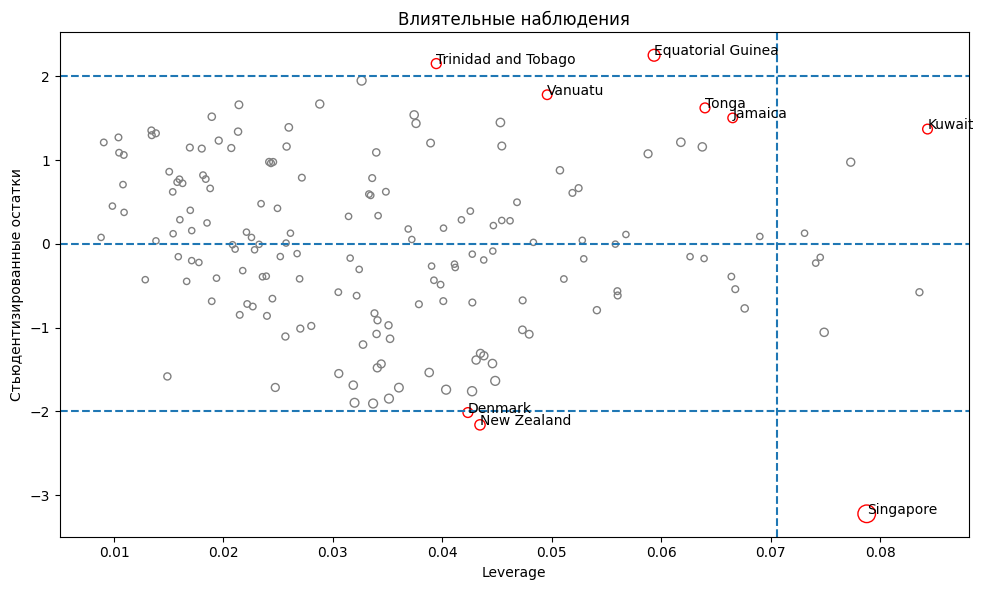

In [19]:
influential = cooks_dist > 4 / len(lab4)

mpl.figure(figsize=(10, 6))
mpl.scatter(leverage, student_resid,
            s=cooks_dist * 1000 + 20,
            facecolors='none',
            edgecolors=np.where(influential, 'red', 'gray'))

for i in np.where(influential)[0]:
    mpl.annotate(lab4.iloc[i]['country'], (leverage[i], student_resid[i]))

mpl.axhline(0, linestyle='--')
mpl.axhline(2, linestyle='--')
mpl.axhline(-2, linestyle='--')
mpl.axvline(2 * (m1.df_model + 1) / len(lab4), linestyle='--')

mpl.xlabel('Leverage')
mpl.ylabel('Стьюдентизированные остатки')
mpl.title('Влиятельные наблюдения')
mpl.tight_layout()
mpl.show()

Кроме этого, можно диагностировать наблюдения, влиятельные с точки зрения изменения конкретного параметра. Для иллюстрации рассмотрим коэффициент при ключевом предикторе dem:

In [20]:
dfbetas = m1.get_influence().dfbetas

coef_index = 1
lab4['dfbetas_dem'] = np.abs(dfbetas[:, coef_index])

dfbeta_dem_data = lab4[np.abs(dfbetas[:, coef_index]) > 2 / np.sqrt(len(lab4))]

dfbeta_dem_data_ordered = dfbeta_dem_data.sort_values('dfbetas_dem', ascending = False)
dfbeta_dem_data_ordered

,country,loggdppc,britcol,dem,stab,fp,cpi,cooks_dist,dfbetas_dem
178,Tonga,8.143227,0,1.550000,0.498140,68.500000,6.908000,0.029747,0.369081
93,Kuwait,10.723268,1,1.283333,0.380597,44.500000,4.983000,0.028698,0.250139
47,Denmark,10.938450,0,44.433334,1.035188,89.000000,0.049667,0.029372,0.245875
85,Jamaica,8.542861,1,14.300000,-0.316884,84.000000,6.099667,0.026670,0.231770
185,Ukraine,7.996317,0,31.283333,-0.096682,46.166668,6.899667,0.010809,0.228668
6,Argentina,9.118225,0,28.466665,0.007387,51.666668,6.549666,0.009952,0.184141
191,Vanuatu,7.962067,0,30.000000,1.337090,76.166664,6.233000,0.027213,0.181301
155,Seychelles,9.314700,1,26.833332,0.827384,41.333332,5.016333,0.013292,0.180320
126,Netherlands,10.749356,0,42.066666,0.895902,87.000000,0.616333,0.018163,0.178209
66,Greece,10.181119,0,37.200001,0.258621,72.000000,5.216333,0.013637,0.176645
